# 03b · Classical baseline on the STYLES: logistic regression

**Why a baseline?** The director asks whether a neural network is worth it, or whether *a simpler classical model would do the job*. To answer, we first need the score of that simple model: it is **the number every neural network must beat** (S08, production checklist: *"Baseline first. A simple model (logistic regression, ...) gives the number to beat"*).

**Link with the course.** Logistic regression is **one neuron** (S02): $z = w^\top x + b$, $a = \sigma(z)$. With $C$ classes we use one neuron per class and a softmax (S04). It is exactly an MLP **without hidden layer**: it can only draw straight boundaries (hyperplanes) in pixel space (S02, "the limit: still a straight line").

| Part | What we do |
|---|---|
| 1 | Data: the team's shared pipeline (same split as every other model) |
| 2 | The floor: chance level |
| 3 | Logistic regression with scikit-learn, regularisation chosen on validation |
| 4 | The same model as one PyTorch layer `nn.Linear`, trained with the 5-line loop |
| 5 | Final test score (once), confusion matrix, CPU cost for the kiosk |

## 0. Setup

In [1]:
import json, math, time, sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from threadpoolctl import threadpool_limits          # installed with scikit-learn

sys.path.insert(0, "../src")                          # so that "import museum_guide" finds the team's code
from museum_guide.data import prepare_subset, make_loaders

SEED = 0
torch.manual_seed(SEED); np.random.seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"

ROOT = Path("..")
LABEL = "style"          # this notebook: the 27 styles (03_baseline = genres)
DOWNSAMPLE = True        # 128 -> 64 px, exactly like the MLP notebook, so that both models see the same inputs
C_GRID = [0.0001, 0.0003, 0.001, 0.01, 0.1]          # inverse regularisation strength of scikit-learn, chosen on validation
EPOCHS_TORCH = 30

FIG_DIR = ROOT / "results" / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
RES_DIR = ROOT / "results"
print("device:", device)

device: cpu


## 1. Data
`prepare_subset` (shared code, `src/museum_guide/data.py`) loads the images, splits them 70 / 15 / 15 with the same class proportions (seed 0) and standardises them with the **training** statistics only.
Like the MLP, we halve the resolution to 64×64 and **flatten** each image into a vector of $3 \times 64 \times 64 = 12\,288$ numbers: logistic regression takes a vector, one weight per pixel value.

In [2]:
data = prepare_subset(LABEL, seed=SEED)
class_names = data["classes"]; C = len(class_names)
X_all, y_all = data["X"], data["y"]
idx = {"train": data["train_idx"], "val": data["val_idx"], "test": data["test_idx"]}
if DOWNSAMPLE:
    X_all = torch.nn.functional.avg_pool2d(X_all, kernel_size=2)       # (N, 3, 128, 128) -> (N, 3, 64, 64)
IMG_SIZE = X_all.shape[-1]

# Flattened NumPy arrays for scikit-learn: one row per image
Xf = {s: X_all[torch.as_tensor(i)].flatten(1).numpy() for s, i in idx.items()}
yf = {s: y_all[torch.as_tensor(i)].numpy() for s, i in idx.items()}
N_IN = Xf["train"].shape[1]

print(C, "classes:", class_names)
for s in Xf: print(f"{s:5s} X {Xf[s].shape}  y {yf[s].shape}")

27 classes: ['Abstract_Expressionism', 'Action_painting', 'Analytical_Cubism', 'Art_Nouveau', 'Baroque', 'Color_Field_Painting', 'Contemporary_Realism', 'Cubism', 'Early_Renaissance', 'Expressionism', 'Fauvism', 'High_Renaissance', 'Impressionism', 'Mannerism_Late_Renaissance', 'Minimalism', 'Naive_Art_Primitivism', 'New_Realism', 'Northern_Renaissance', 'Pointillism', 'Pop_Art', 'Post_Impressionism', 'Realism', 'Rococo', 'Romanticism', 'Symbolism', 'Synthetic_Cubism', 'Ukiyo_e']
train X (5212, 12288)  y (5212,)
val   X (1118, 12288)  y (1118,)
test  X (1118, 12288)  y (1118,)


## 2. The floor: chance level
With $C$ balanced classes, answering at random gives an accuracy of $1/C$. Any model must be clearly above it.

In [3]:
chance = 1 / C
majority = np.bincount(yf["train"]).argmax()
majority_acc = accuracy_score(yf["val"], np.full_like(yf["val"], majority))
print(f"chance level 1/C = {chance:.3f} | 'always the most frequent class' on validation = {majority_acc:.3f}")

chance level 1/C = 0.037 | 'always the most frequent class' on validation = 0.040


## 3. Logistic regression with scikit-learn
`LogisticRegression` minimises the cross-entropy (the log loss of S02, generalised to $C$ classes in S04) plus an L2 penalty on the weights.
`C` is the **inverse** of the regularisation strength: small `C` = strong regularisation. With 12 288 weights per class and only ~2 300 training images, the model can easily over-fit, so we **choose `C` on the validation set** (never on the test set, S04).

C = 0.0001 train acc 0.290 | val acc 0.112 | fit 264 s
C = 0.0003 train acc 0.427 | val acc 0.102 | fit 270 s
C = 0.001  train acc 0.670 | val acc 0.098 | fit 290 s
C = 0.01   train acc 0.972 | val acc 0.095 | fit 522 s
C = 0.1    train acc 0.996 | val acc 0.099 | fit 522 s

chosen on validation: C = 0.0001  (val acc 0.112)


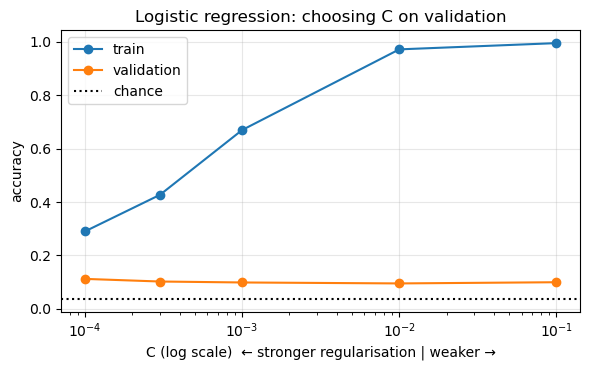

In [4]:
runs = {}
for c_reg in C_GRID:
    clf = LogisticRegression(C=c_reg, max_iter=1000)
    t0 = time.time()
    clf.fit(Xf["train"], yf["train"])
    fit_s = time.time() - t0
    runs[c_reg] = {"model": clf, "fit_s": fit_s,
                   "train_acc": clf.score(Xf["train"], yf["train"]),
                   "val_acc": clf.score(Xf["val"], yf["val"])}
    print(f"C = {c_reg:<6g} train acc {runs[c_reg]['train_acc']:.3f} | val acc {runs[c_reg]['val_acc']:.3f} | fit {fit_s:.0f} s")

best_C = max(runs, key=lambda c: runs[c]["val_acc"])
logreg = runs[best_C]["model"]
print(f"\nchosen on validation: C = {best_C}  (val acc {runs[best_C]['val_acc']:.3f})")

plt.figure(figsize=(6, 3.8))
plt.plot(C_GRID, [runs[c]["train_acc"] for c in C_GRID], "o-", label="train")
plt.plot(C_GRID, [runs[c]["val_acc"] for c in C_GRID], "o-", label="validation")
plt.axhline(chance, ls=":", c="k", label="chance")
plt.xscale("log"); plt.xlabel("C (log scale)  ← stronger regularisation | weaker →"); plt.ylabel("accuracy")
plt.title("Logistic regression: choosing C on validation"); plt.legend(); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(FIG_DIR / "baseline_style_choose_C.png", dpi=150); plt.show()

**Reading.** With 27 styles, chance level is 1/27 ≈ 0.037. The best validation accuracy is **0.112, with C = 0.0001** (the strongest regularisation). That is about 3 times chance, but still very low.

- **Over-fitting gets worse as C increases.** Train accuracy goes from 0.29 to 0.996, while validation accuracy stays flat around 0.10. With 12,288 pixel inputs per image and about 5,700 training images, the model can memorise the training set without learning anything that transfers to new images.
- **Regularisation helps a little but cannot fix it.** Validation accuracy only moves between 0.095 and 0.112. The problem is not the choice of C: raw pixels simply do not carry the information that defines a style (brushwork, composition, period).
- **The chosen C is at the edge of the grid.** A smaller C could do slightly better, but the gain would be tiny: the validation curve is almost flat. We keep C = 0.0001 to limit computation time (each fit takes 4 to 9 minutes on CPU).

This is the floor that the MLP and the ResNet must beat on the styles.

## 4. The same model in PyTorch: one `nn.Linear` layer
To show that the baseline is really "one neuron per class", we build it with PyTorch primitives and train it with **the five lines** of the course (S04): forward, loss, `zero_grad`, `backward`, `step`.
`nn.CrossEntropyLoss` receives the raw logits and applies the softmax itself. `weight_decay` plays the role of scikit-learn's L2 penalty.

331,803 parameters = 27 x (12288 + 1)
epoch  1 | train loss 3.272 acc 0.070 | val loss 3.297 acc 0.058
epoch  2 | train loss 3.222 acc 0.076 | val loss 3.256 acc 0.065
epoch  3 | train loss 3.192 acc 0.082 | val loss 3.233 acc 0.072
epoch  4 | train loss 3.168 acc 0.088 | val loss 3.217 acc 0.074
epoch  5 | train loss 3.148 acc 0.096 | val loss 3.206 acc 0.081
epoch  6 | train loss 3.132 acc 0.101 | val loss 3.196 acc 0.081
epoch  7 | train loss 3.117 acc 0.105 | val loss 3.189 acc 0.088
epoch  8 | train loss 3.104 acc 0.109 | val loss 3.184 acc 0.089
epoch  9 | train loss 3.092 acc 0.113 | val loss 3.179 acc 0.091
epoch 10 | train loss 3.081 acc 0.118 | val loss 3.175 acc 0.089
epoch 11 | train loss 3.071 acc 0.126 | val loss 3.172 acc 0.091
epoch 12 | train loss 3.061 acc 0.126 | val loss 3.169 acc 0.091
epoch 13 | train loss 3.052 acc 0.132 | val loss 3.166 acc 0.091
epoch 14 | train loss 3.044 acc 0.133 | val loss 3.164 acc 0.095
epoch 15 | train loss 3.035 acc 0.138 | val loss 3.1

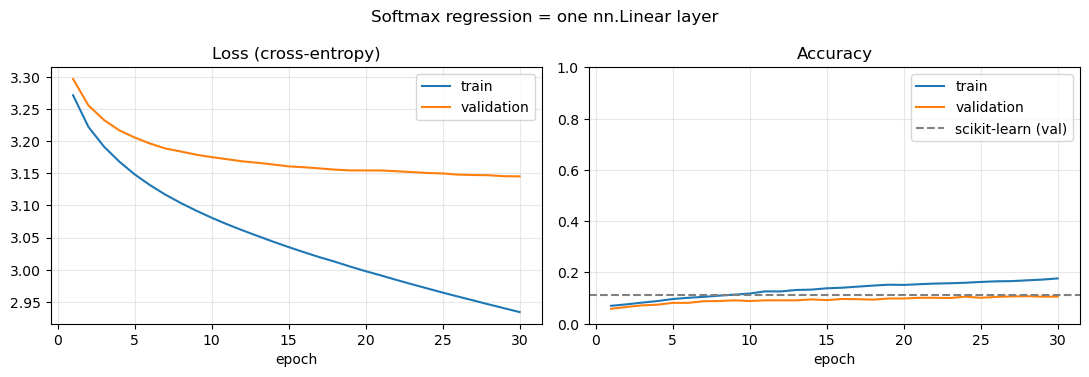

best validation accuracy: PyTorch 0.107 vs scikit-learn 0.112


In [5]:
train_loader, val_loader, test_loader = make_loaders(X_all, y_all, idx["train"], idx["val"], idx["test"])

torch.manual_seed(SEED)
softmax_reg = nn.Sequential(nn.Flatten(), nn.Linear(N_IN, C)).to(device)   # z = W x + b, one row of W per class
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(softmax_reg.parameters(), lr=0.0001, weight_decay=1e-2)   # values found on the genres (03_baseline)
print(f"{sum(p.numel() for p in softmax_reg.parameters()):,} parameters = {C} x ({N_IN} + 1)")

def evaluate(model, loader):
    model.eval(); total_loss, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            total_loss += loss_fn(logits, yb).item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item(); n += len(yb)
    return total_loss / n, correct / n

hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
for epoch in range(1, EPOCHS_TORCH + 1):
    softmax_reg.train()
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = softmax_reg(xb)          # 1. forward
        loss = loss_fn(logits, yb)        # 2. loss
        optimizer.zero_grad()             # 3. reset the gradients
        loss.backward()                   # 4. backpropagation
        optimizer.step()                  # 5. update
    tl, ta = evaluate(softmax_reg, train_loader); vl, va = evaluate(softmax_reg, val_loader)
    for k, v in zip(hist, [tl, vl, ta, va]): hist[k].append(v)
    print(f"epoch {epoch:2d} | train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8)); ep = range(1, EPOCHS_TORCH + 1)
ax[0].plot(ep, hist["train_loss"], label="train"); ax[0].plot(ep, hist["val_loss"], label="validation")
ax[1].plot(ep, hist["train_acc"], label="train"); ax[1].plot(ep, hist["val_acc"], label="validation")
ax[1].axhline(runs[best_C]["val_acc"], ls="--", c="grey", label="scikit-learn (val)")
ax[0].set(title="Loss (cross-entropy)", xlabel="epoch"); ax[1].set(title="Accuracy", xlabel="epoch", ylim=(0, 1))
for a in ax: a.legend(); a.grid(alpha=.3)
fig.suptitle("Softmax regression = one nn.Linear layer"); fig.tight_layout()
fig.savefig(FIG_DIR / "baseline_style_pytorch_curves.png", dpi=150); plt.show()
print(f"best validation accuracy: PyTorch {max(hist['val_acc']):.3f} vs scikit-learn {runs[best_C]['val_acc']:.3f}")

**Reading.** The PyTorch model is the same logistic regression: one `nn.Linear` layer with 27 × (12,288 + 1) = 331,803 parameters, trained with cross-entropy and SGD.

- **Sanity check at epoch 1.** The loss starts at 3.27–3.30, which is ln(27) ≈ 3.30: the model starts by guessing uniformly over the 27 styles, as expected (S06).
- **The learning rate is fine.** Both curves decrease smoothly, with no oscillation and no explosion, so lr = 0.0001 is neither too large nor too small.
- **Over-fitting is starting.** Train loss keeps going down (3.27 → 2.93), but validation loss flattens around 3.15 after about 20 epochs. The gap between the two curves keeps growing: the model is learning details of the training images that do not generalise.
- **Same result as scikit-learn.** Best validation accuracy is 0.107 with PyTorch vs 0.112 with scikit-learn. The two implementations of the same model agree (the gap is within the noise of the validation set), which confirms that the low score comes from raw pixels, not from the code.

## 5. Final evaluation on the test set (once) and cost for the kiosk
The reported baseline is the scikit-learn model with the `C` chosen on validation. The test set is used only now.
The kiosk has a modest CPU: we time **one prediction for one image with one CPU thread**.

TEST accuracy = 0.114   (chance 0.037)


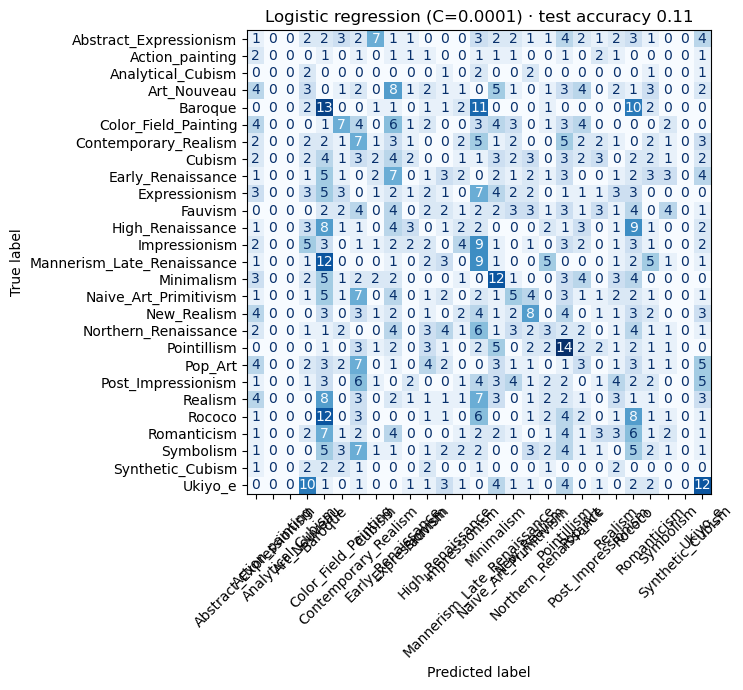

  Pointillism            0.31
  Baroque                0.29
  Minimalism             0.27
  Ukiyo_e                0.27
  Mannerism_Late_Renaissance 0.20
  New_Realism            0.18
  Rococo                 0.18
  Color_Field_Painting   0.16
  Contemporary_Realism   0.16
  Early_Renaissance      0.16
  Naive_Art_Primitivism  0.11
  Impressionism          0.09
  Art_Nouveau            0.07
  Northern_Renaissance   0.07
  Pop_Art                0.07
  Realism                0.07
  Cubism                 0.04
  Fauvism                0.04
  Abstract_Expressionism 0.02
  Expressionism          0.02
  High_Renaissance       0.02
  Post_Impressionism     0.02
  Romanticism            0.02
  Symbolism              0.02
  Action_painting        0.00
  Analytical_Cubism      0.00
  Synthetic_Cubism       0.00
most frequent mistake: true 'Mannerism_Late_Renaissance' predicted as 'Baroque' (12 times)


In [6]:
y_pred = logreg.predict(Xf["test"])
test_acc = accuracy_score(yf["test"], y_pred)
print(f"TEST accuracy = {test_acc:.3f}   (chance {chance:.3f})")

cm = confusion_matrix(yf["test"], y_pred, labels=range(C))
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, xticks_rotation=45, colorbar=False, cmap="Blues")
ax.set_title(f"Logistic regression (C={best_C}) · test accuracy {test_acc:.2f}"); fig.tight_layout()
fig.savefig(FIG_DIR / "baseline_style_confusion_test.png", dpi=150); plt.show()

per_class = cm.diagonal() / cm.sum(axis=1)
for name, acc in sorted(zip(class_names, per_class), key=lambda t: -t[1]):
    print(f"  {name:22s} {acc:.2f}")
off = cm.copy(); np.fill_diagonal(off, 0); i, j = np.unravel_index(off.argmax(), off.shape)
if off[i, j] > 0:
    print(f"most frequent mistake: true '{class_names[i]}' predicted as '{class_names[j]}' ({off[i, j]} times)")

**Reading.** Test accuracy is **0.114** (chance 0.037), very close to validation (0.112): the test set confirms the validation estimate, so there is no sign that we over-fitted the choice of C.

- **What the model gets right.** The best styles have a strong visual signature at the pixel level: Pointillism (0.31, dense dots of bright colour), Baroque (0.29, dark backgrounds and strong contrast), Minimalism (0.27, large flat areas) and Ukiyo-e (0.27, flat colours and light backgrounds). The model mostly reads **global colour and brightness**, not brushwork or content.
- **Mistakes make historical sense.** Old, dark paintings are mixed together: Mannerism is predicted as Baroque 12 times (the most frequent mistake), Rococo as Baroque 12 times, and Baroque as Mannerism or Rococo 21 times. These are three neighbouring periods with similar palettes. Ukiyo-e is predicted as Art Nouveau 10 times, which is not absurd: Art Nouveau was strongly influenced by Japanese prints.
- **Small classes are never predicted.** Action painting, Analytical Cubism and Synthetic Cubism get 0.00. They have far fewer images than the other styles (about 10 in the test set), and their columns are almost empty: the model learns to favour the large classes. This is the class-imbalance problem seen in S06.
- **Conclusion.** Raw pixels capture colour and contrast, but not the features that define a style. This is the floor the ResNet must beat.

In [7]:
x_one = Xf["test"][:1]
with threadpool_limits(limits=1):                     # one CPU thread, like a modest kiosk
    for _ in range(10): logreg.predict(x_one)
    times = []
    for _ in range(200):
        t0 = time.perf_counter(); logreg.predict(x_one); times.append((time.perf_counter() - t0) * 1000)
ms = float(np.median(times))

n_parameters = logreg.coef_.size + logreg.intercept_.size
result = {"model": "baseline_logreg_style", "label": LABEL, "test_accuracy": round(float(test_acc), 4), "cpu_ms_per_image": round(ms, 3),
          "n_parameters": int(n_parameters), "size_mb": round(n_parameters * 8 / 1e6, 1),
          "train_time_s": round(runs[best_C]["fit_s"], 1), "n_classes": C, "img_size": IMG_SIZE, "C": best_C,
          "val_accuracy": round(float(runs[best_C]["val_acc"]), 4)}
print(json.dumps(result, indent=2))
(RES_DIR / "baseline_logreg_style.json").write_text(json.dumps(result, indent=2))

{
  "model": "baseline_logreg_style",
  "label": "style",
  "test_accuracy": 0.1145,
  "cpu_ms_per_image": 0.135,
  "n_parameters": 331803,
  "size_mb": 2.7,
  "train_time_s": 263.9,
  "n_classes": 27,
  "img_size": 64,
  "C": 0.0001,
  "val_accuracy": 0.1118
}


261

**Reading.** The baseline costs almost nothing at inference: **0.135 ms per image** on one CPU thread and **2.7 MB** for 331,803 parameters. Training took about 4.5 minutes on CPU. With 0.114 test accuracy (3 times chance), it is cheap but far too inaccurate for a museum guide: it gives the wrong style for about 9 paintings out of 10.